# Every RAW and confirmed file outside LR-Raman, by excitation wavelength

This notebook describes a set of files: every export in the RRUFF archives that says RAW and whose
identification is confirmed. The `LR-Raman` archive is left out, since it is a separate library
rather than one of the quality-rated archives. Nothing else is filtered: no window, no trim, and no
restriction on the excitation wavelength, so the set holds whatever range each file happens to span.

The table at the end counts the files by the excitation wavelength they were written at.


## 1. Setting up

The archives are looked for under `~/Desktop/raman_data` unless `RRUFF_DATA` points somewhere else.
The seven archives the set is taken from are named here, and so are the header fields it is filtered
on.


In [1]:
from __future__ import annotations

import os
import re
import time
from pathlib import Path

import pandas as pd

# The seven quality-rated archives. LR-Raman is not one of them: it is a separate library of
# Raman spectra, so it is left out of the set.
ARCHIVES = [
    "excellent_oriented",
    "excellent_unoriented",
    "fair_oriented",
    "fair_unoriented",
    "poor_unoriented",
    "unrated_oriented",
    "unrated_unoriented",
]

# FILETYPE names the export kind, so a RAW file is picked out by that field rather than by the
# file name. STATUS carries RRUFF's sentence about the identification; a sentence recorded as
# "...is not yet confirmed", as the bare "Unconfirmed", or as a wording without the "yet" is
# matched by one of the three markers read as a substring.
UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")

DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

# Used by the reader below, so they are defined next to the paths rather than inside it.
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
LEADING = "+-."

absent = [name for name in ARCHIVES if not (DATA_ROOT / name).is_dir()]
if absent:
    raise FileNotFoundError(f"these archive directories are missing under {DATA_ROOT}: {absent}")

print(f"reading {len(ARCHIVES)} archives from {DATA_ROOT}")
for name in ARCHIVES:
    print(f"  {name:22s} {len(list((DATA_ROOT / name).glob('*.txt'))):7,d} files")


reading 7 archives from /home/raj/Desktop/raman_data
  excellent_oriented       7,668 files
  excellent_unoriented    11,415 files
  fair_oriented               25 files
  fair_unoriented          2,951 files
  poor_unoriented          1,639 files
  unrated_oriented         3,778 files
  unrated_unoriented         639 files


## 2. Reading one export

A file is a `##KEY=value` block, then the data rows. The traps the reader has to survive are the
ones the other notebooks describe: a value wrapped onto the following line, a key written twice, and
comment lines inside the data block. The reader is repeated here in full so that this notebook runs
on its own.

`read_spectrum` returns the header fields and a few facts about the data block, and it stops at the
first data row, which is what makes the pass over the archives in section 3 cheap. Nothing here
reads the data rows themselves, so no spectrum is loaded.


In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the header fields as a dict, and a dict describing the data block with the
        keys points, x_min, x_max, wrapped_values, repeated_keys, comment_notes,
        separator, crlf and encoding.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout


## 3. The files the set keeps

Every file in the seven archives is read for its header. A file is kept when its `FILETYPE` says RAW
and its `STATUS` sentence does not carry any of the unconfirmed markers. The table counts the four
combinations of the two fields, so the size of the pool the kept set comes out of is on the page
next to the size of the set itself.


In [3]:
started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DATA_ROOT / archive).glob("*.txt")):
        header, _ = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        records.append({
            "archive": archive,
            "path": str(path),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            # The file name carries the excitation wavelength the export was written at,
            # in the fourth field of its "__"-separated stem.
            "wavelength": path.stem.split("__")[3],
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "status": header.get("STATUS", ""),
        })

pool = pd.DataFrame.from_records(records)
print(f"read {len(pool):,} headers in {time.time() - started:.1f}s")
print()

unconfirmed = pool.status.str.strip().str.lower().map(
    lambda sentence: any(marker in sentence for marker in UNCONFIRMED_MARKERS))
raw = pool.kind == "RAW"
kept = pool[raw & ~unconfirmed].copy()

counts = pd.DataFrame({
    "confirmed": [int((raw & ~unconfirmed).sum()), int((~raw & ~unconfirmed).sum())],
    "unconfirmed": [int((raw & unconfirmed).sum()), int((~raw & unconfirmed).sum())],
}, index=["RAW", "Processed"])
counts["files"] = counts.sum(axis=1)
counts.loc["all files"] = counts.sum()
counts = counts.astype(int)

print(f"the pool:     {len(pool):7,d} files")
print(f"the kept set: {len(kept):7,d} files ({len(kept) / len(pool) * 100:.1f}% of the pool)")
print()
print(counts.to_string())
print()
print("the kept set by archive:")
print(kept.groupby("archive").size().to_string())


read 28,115 headers in 13.9s

the pool:      28,115 files
the kept set:  13,154 files (46.8% of the pool)

           confirmed  unconfirmed  files
RAW            13154          954  14108
Processed      13054          953  14007
all files      26208         1907  28115

the kept set by archive:
archive
excellent_oriented      3799
excellent_unoriented    5242
fair_oriented             12
fair_unoriented         1193
poor_unoriented          630
unrated_oriented        1927
unrated_unoriented       351


## 4. The number of files per excitation wavelength

One row per excitation wavelength the kept files were written at, largest group first. The value is
the fourth field of the file name, so it is reported as the file writes it.


In [4]:
per_laser = (kept.groupby("wavelength").size()
            .rename("files")
            .sort_values(ascending=False)
            .to_frame())
per_laser.index.name = "laser (nm), as written in the file name"

print(f"{int(per_laser['files'].sum()):,} files over {len(per_laser)} laser excitations")
print()
print(per_laser.to_string())

13,154 files over 18 laser excitations

                                         files
laser (nm), as written in the file name       
514                                       6222
532                                       3509
780                                       2384
785                                        981
633                                         12
632                                         12
                                            11
514-5                                       10
532-6                                        2
488                                          2
515                                          2
458                                          1
523                                          1
53                                           1
632-8                                        1
532SP9                                       1
638                                          1
784                                          1


## 5. The number of minerals per excitation wavelength

This groups the kept set by the excitation wavelength, as the section above does, and counts
minerals rather than files. One row per excitation, largest group first, giving the number of files,
the number of distinct minerals those files name, and the mean number of files per mineral. A file
whose name leaves the wavelength field empty sits under the empty label, the way the table above
prints it.

A mineral written at more than one excitation is counted under each of them, so the mineral column
is per excitation and its sum runs past the number of distinct minerals in the whole set. The last
row of the table gives that number.


In [5]:
per_laser_minerals = (kept.groupby("wavelength")
                      .agg(files=("path", "size"), minerals=("mineral", "nunique"))
                      .sort_values("files", ascending=False, kind="stable"))
per_laser_minerals.index.name = "laser (nm), as written in the file name"
per_laser_minerals["files per mineral"] = (per_laser_minerals["files"]
                                           / per_laser_minerals["minerals"])

whole = pd.DataFrame({
    "files": [int(per_laser_minerals["files"].sum())],
    "minerals": [int(kept["mineral"].nunique())],
}, index=["all excitations"])
whole["files per mineral"] = whole["files"] / whole["minerals"]
table = pd.concat([per_laser_minerals, whole])

print(f"{int(table.loc['all excitations', 'files']):,} files over "
      f"{len(per_laser_minerals)} laser excitations, across "
      f"{int(table.loc['all excitations', 'minerals']):,} minerals")
print()
print(table.round({"files per mineral": 2}).to_string())
print()
print("a mineral written at more than one excitation is counted under each of them, so the "
      "minerals column adds up past the distinct minerals in the set")


13,154 files over 18 laser excitations, across 2,116 minerals

                 files  minerals  files per mineral
514               6222       355              17.53
532               3509      2044               1.72
780               2384      1509               1.58
785                981       754               1.30
632                 12        10               1.20
633                 12        11               1.09
                    11        11               1.00
514-5               10         8               1.25
488                  2         2               1.00
515                  2         2               1.00
532-6                2         1               2.00
458                  1         1               1.00
523                  1         1               1.00
53                   1         1               1.00
532SP9               1         1               1.00
632-8                1         1               1.00
638                  1         1               1.00
7

## 6. Where the files at 514, 532 and 780 nm come from

The three excitations that hold most of the set, counted by the archive each file was taken from.
The archives are the RRUFF folders the files were read out of, so a row says how that excitation is
spread over the seven of them. The last row totals the three.


In [6]:
MAIN_LASERS = ["514", "532", "780"]

sources = (kept[kept.wavelength.isin(MAIN_LASERS)]
           .groupby(["wavelength", "archive"]).size()
           .unstack("archive", fill_value=0)
           .reindex(index=MAIN_LASERS, columns=ARCHIVES, fill_value=0))
sources["files"] = sources.sum(axis=1)
sources.loc["the three"] = sources.sum()
sources.index.name = "laser (nm)"
sources.columns.name = None

print(f"{int(sources.loc['the three', 'files']):,} files at 514, 532 and 780 nm, "
      f"of the {len(kept):,} in the set")
print()
print(sources.to_string())

12,115 files at 514, 532 and 780 nm, of the 13,154 in the set

            excellent_oriented  excellent_unoriented  fair_oriented  fair_unoriented  poor_unoriented  unrated_oriented  unrated_unoriented  files
laser (nm)                                                                                                                                        
514                       3793                   389             12               66                9              1916                  37   6222
532                          0                  2612              0              533              209                 4                 151   3509
780                          0                  1584              0              406              298                 0                  96   2384
the three                 3793                  4585             12             1005              516              1920                 284  12115


## 7. The minerals at 514, 532, 780 and 785 nm, counted by archive

The four excitations holding the most files, with the minerals they name counted in each archive.
785 nm is added to the three of the section above because it is the fourth largest group, at 981
files. A cell gives the number of distinct minerals that one archive contributes at one excitation.

A mineral recorded in two archives is counted under both, so a row adds up past the number of
distinct minerals at that excitation, which the last column gives. The closing row counts each
archive over all four excitations.


In [7]:
# The four excitations holding the most files. 785 nm is the fourth largest group, so it joins the
# three the section above uses.
TOP_LASERS = ["514", "532", "780", "785"]

top = kept[kept["wavelength"].isin(TOP_LASERS)]

by_archive = (top.groupby(["wavelength", "archive"])["mineral"].nunique()
              .unstack("archive", fill_value=0)
              .reindex(index=TOP_LASERS, columns=ARCHIVES, fill_value=0))
by_archive["minerals"] = (top.groupby("wavelength")["mineral"].nunique()
                          .reindex(TOP_LASERS, fill_value=0))

totals = {archive: int(top["mineral"][top["archive"] == archive].nunique())
          for archive in ARCHIVES}
totals["minerals"] = int(top["mineral"].nunique())
by_archive.loc["the four"] = pd.Series(totals)

by_archive.index.name = "laser (nm)"
by_archive.columns.name = None

print(f"{int(top['mineral'].nunique()):,} distinct minerals over {len(top):,} files at these "
      f"four excitations")
print()
print(by_archive.to_string())
print()
print("a mineral recorded in two archives is counted under both, so a row adds up past the "
      "minerals column, which counts each mineral once per excitation")


2,080 distinct minerals over 13,096 files at these four excitations

            excellent_oriented  excellent_unoriented  fair_oriented  fair_unoriented  poor_unoriented  unrated_oriented  unrated_unoriented  minerals
laser (nm)                                                                                                                                           
514                        210                   239              4               58                9               215                  31       355
532                          0                  1554              0              436              176                 2                 129      2044
780                          0                  1036              0              356              247                 0                  79      1509
785                          3                   491              0              160              105                 2                  45       754
the four                   210 

## 8. The three largest clusters of each archive

An archive and one excitation together make a cluster: the files that archive contributes at that
excitation. Every cluster the set holds is counted for its files and for the distinct minerals those
files name, and each archive is then reduced to its three largest clusters by file count.

The blocks are one per archive. The line over each block gives the archive's own totals, so its
three clusters can be read against the whole folder they come from. An archive holding files at
fewer than three excitations has fewer rows, and an archive whose files are all at one excitation,
such as `fair_oriented`, has a single row. A file whose name leaves the wavelength field empty
sits under the empty label, the way the tables above print it.


In [8]:
clusters = (kept.groupby(["archive", "wavelength"])
            .agg(files=("path", "size"), minerals=("mineral", "nunique"))
            .reset_index())
clusters["rank"] = (clusters.groupby("archive")["files"]
                    .rank(method="first", ascending=False).astype(int))
largest = clusters[clusters["rank"] <= 3]

print(f"{len(clusters):,} clusters over {clusters['archive'].nunique()} archives; the three "
      f"largest of each archive make {len(largest):,} of them")
print()

for archive, group in largest.groupby("archive", sort=True):
    whole = kept[kept["archive"] == archive]
    print(f"{archive}  ({len(whole):,} files, {whole['mineral'].nunique():,} minerals)")
    print(group.sort_values("files", ascending=False)[["wavelength", "files", "minerals"]]
          .rename(columns={"wavelength": "laser (nm)"})
          .to_string(index=False))
    print()


44 clusters over 7 archives; the three largest of each archive make 19 of them

excellent_oriented  (3,799 files, 211 minerals)
laser (nm)  files  minerals
       514   3793       210
     514-5      3         1
       785      3         3

excellent_unoriented  (5,242 files, 1,701 minerals)
laser (nm)  files  minerals
       532   2612      1554
       780   1584      1036
       785    639       491

fair_oriented  (12 files, 4 minerals)
laser (nm)  files  minerals
       514     12         4

fair_unoriented  (1,193 files, 708 minerals)
laser (nm)  files  minerals
       532    533       436
       780    406       356
       785    178       160

poor_unoriented  (630 files, 390 minerals)
laser (nm)  files  minerals
       780    298       247
       532    209       176
       785    114       105

unrated_oriented  (1,927 files, 217 minerals)
laser (nm)  files  minerals
       514   1916       215
       532      4         2
                3         3

unrated_unoriented  (351 f

## 9. What each cluster shares with the other archives at its excitation

One row per cluster and its closest match at the same excitation, ordered by the size of the
overlap, largest first. The overlap is counted only between clusters at the same excitation, which
is the case where two archives can be compared on equal footing: a mineral counts when this cluster
holds it and another archive holds it at the same wavelength.

- `cluster`: one archive and one excitation, written as `archive @ wavelength`.
- `most overlapped with`: the cluster at this excitation sharing the most with `cluster`.
- `overlap with this cluster`: the number of minerals the two have in common.

When two clusters are each other's closest match the pair would otherwise fill two rows, one from
each side, so only the first is kept and the mirror is dropped. A cluster standing alone at its
excitation, with no other archive writing at that wavelength, has nothing to compare against: its
partner reads `-` and its overlap is 0. A few file names carry no excitation at all, and those
clusters are written as `archive @ no laser`.


In [9]:
def cluster_name(archive, wavelength):
    """The name of one cluster: its archive and the excitation its files were written at.

    An export's excitation field is sometimes empty, and such a cluster is named without one
    rather than left with a dangling separator.

    Args:
        archive (str): the folder the cluster's files come from.
        wavelength (str): the excitation as written in the file names, possibly empty.

    Returns:
        str: the cluster written as `archive @ wavelength`.
    """
    return f"{archive} @ {wavelength or 'no laser'}"


keyed = kept.groupby(["archive", "wavelength"])["mineral"]
cluster_minerals = {key: set(values) for key, values in keyed}

rows, listed = [], set()
for (archive, wavelength), minerals in cluster_minerals.items():
    name = cluster_name(archive, wavelength)
    others = [(key, held) for key, held in cluster_minerals.items()
              if key[1] == wavelength and key[0] != archive]
    if others:
        partner, held = max(others, key=lambda item: (len(minerals & item[1]), item[0]))
        overlap = len(minerals & held)
        partner_name = cluster_name(partner[0], partner[1])
    else:
        overlap, partner_name = 0, "-"
    # Two clusters that are each other's closest match give the same pair from both sides, so the
    # pair is reduced to a single row and the mirrored one is skipped.
    pair = tuple(sorted((name, partner_name)))
    if pair in listed:
        continue
    listed.add(pair)
    rows.append({
        "cluster": name,
        "most overlapped with": partner_name,
        "overlap with this cluster": overlap,
    })

profile = (pd.DataFrame.from_records(rows)
           .sort_values(["overlap with this cluster", "cluster"], ascending=[False, True])
           .reset_index(drop=True))

alone = int((profile["most overlapped with"] == "-").sum())
mutual = len(cluster_minerals) - len(profile)

print(f"{len(cluster_minerals)} clusters, {alone} standing alone at their excitation")
print(f"{len(profile)} rows, {mutual} fewer than there are clusters: that many pairs pick "
      f"each other, and each of those is listed once")
print()
print(profile.to_string(index=False))
print()
print("the overlap counts the minerals one cluster holds that another archive also holds at the "
      "same excitation, and it is taken against the single best-matching cluster of another "
      "archive. Two clusters that are each other's closest match are listed once, not twice")


44 clusters, 10 standing alone at their excitation
36 rows, 8 fewer than there are clusters: that many pairs pick each other, and each of those is listed once

                        cluster        most overlapped with  overlap with this cluster
       excellent_oriented @ 514      unrated_oriented @ 514                        199
     excellent_unoriented @ 514    excellent_oriented @ 514                        149
     excellent_unoriented @ 532       fair_unoriented @ 532                        140
     excellent_unoriented @ 780       fair_unoriented @ 780                         96
          poor_unoriented @ 780       fair_unoriented @ 780                         51
          poor_unoriented @ 532       fair_unoriented @ 532                         43
       unrated_unoriented @ 532  excellent_unoriented @ 532                         37
          fair_unoriented @ 514      unrated_oriented @ 514                         33
       unrated_unoriented @ 780  excellent_unoriented @ 7

## 10. Section 9's clusters, split by excitation

Section 9 compares a cluster only with the other archives at its own excitation, so its rows never
cross an excitation. They are split back out here, one table per laser, which is the view where
every row of a table is comparable with every other row in it.

The tables run largest first by the number of clusters at the excitation, and the rows within a
table are ordered by the size of the overlap. The heading of a table gives the excitation, the
number of files recorded at it, and the number of clusters those files make. A table has one row
per cluster, except that the mirror of a mutual pair is dropped, so it can be a row short of its
cluster count. An excitation whose files all come from one archive makes a single cluster with
nothing to compare against, so its table holds one row with no partner.

The excitation field is empty in some file names, and those files form a group of their own, listed
here as `no laser named`.


In [10]:
# Section 9 compares a cluster only with the other archives at its own excitation, so its rows fall
# into groups that never cross an excitation. Split them out and print one table per laser.
laser_of = {cluster_name(archive, wavelength): wavelength
            for archive, wavelength in cluster_minerals}
grouped = profile.assign(laser=profile["cluster"].map(laser_of))

cluster_count = {}
for archive, wavelength in cluster_minerals:
    cluster_count[wavelength] = cluster_count.get(wavelength, 0) + 1

files_per_laser = kept.groupby("wavelength").size()
order = sorted(cluster_count, key=lambda laser: (-cluster_count[laser], laser))

print(f"section 9's {len(profile)} rows over {len(order)} excitations, the largest group of "
      f"clusters first")
print()

for laser in order:
    block = (grouped[grouped["laser"] == laser].drop(columns="laser")
             .sort_values("overlap with this cluster", ascending=False, kind="stable"))
    files, clusters = int(files_per_laser[laser]), cluster_count[laser]
    label = f"{laser} nm" if laser else "no laser named"
    print(f"{label}  ({files:,} {'file' if files == 1 else 'files'}, "
          f"{clusters} {'cluster' if clusters == 1 else 'clusters'})")
    print(block.to_string(index=False))
    print()


section 9's 36 rows over 18 excitations, the largest group of clusters first

514 nm  (6,222 files, 7 clusters)
                   cluster       most overlapped with  overlap with this cluster
  excellent_oriented @ 514     unrated_oriented @ 514                        199
excellent_unoriented @ 514   excellent_oriented @ 514                        149
     fair_unoriented @ 514     unrated_oriented @ 514                         33
  unrated_unoriented @ 514 excellent_unoriented @ 514                         19
       fair_oriented @ 514   excellent_oriented @ 514                          4
     poor_unoriented @ 514     unrated_oriented @ 514                          3

785 nm  (981 files, 6 clusters)
                   cluster       most overlapped with  overlap with this cluster
excellent_unoriented @ 785      fair_unoriented @ 785                         22
  unrated_unoriented @ 785 excellent_unoriented @ 785                          9
     poor_unoriented @ 785 excellent_unorient

514-5 nm  (10 files, 3 clusters)
                     cluster    most overlapped with  overlap with this cluster
  excellent_oriented @ 514-5 fair_unoriented @ 514-5                          0
excellent_unoriented @ 514-5 fair_unoriented @ 514-5                          0

632 nm  (12 files, 3 clusters)
               cluster     most overlapped with  overlap with this cluster
 fair_unoriented @ 632 unrated_unoriented @ 632                          1
unrated_oriented @ 632 unrated_unoriented @ 632                          0

633 nm  (12 files, 3 clusters)
                   cluster     most overlapped with  overlap with this cluster
excellent_unoriented @ 633 unrated_unoriented @ 633                          0
     fair_unoriented @ 633 unrated_unoriented @ 633                          0

458 nm  (1 file, 1 cluster)
                   cluster most overlapped with  overlap with this cluster
excellent_unoriented @ 458                    -                          0

488 nm  (2 files, 1 c

## 11. The spectra of four minerals both archives hold at 532 nm

Section 9 counts the minerals `excellent_unoriented` and `fair_unoriented` both hold at 532 nm, and
this section reads the files of four of them and draws them, so the sharing can be looked at rather
than only counted.

One panel per file, laid out so a row is one mineral. The first two columns are the two archives as
recorded, keeping the file's own intensities; the last two are the same files divided by their own
largest intensity. Every panel carries its own scale, so the recorded ones are read for the size of
the spectrum and the normalised ones for its shape. The title of each panel gives the mineral, the
archive, the treatment, and the RRUFF id of the file drawn.

The minerals shown are the first of those where each archive brings a single file, in alphabetical
order, so every row holds exactly one file per archive. How many of the shared minerals are of that
kind is printed under the figure.


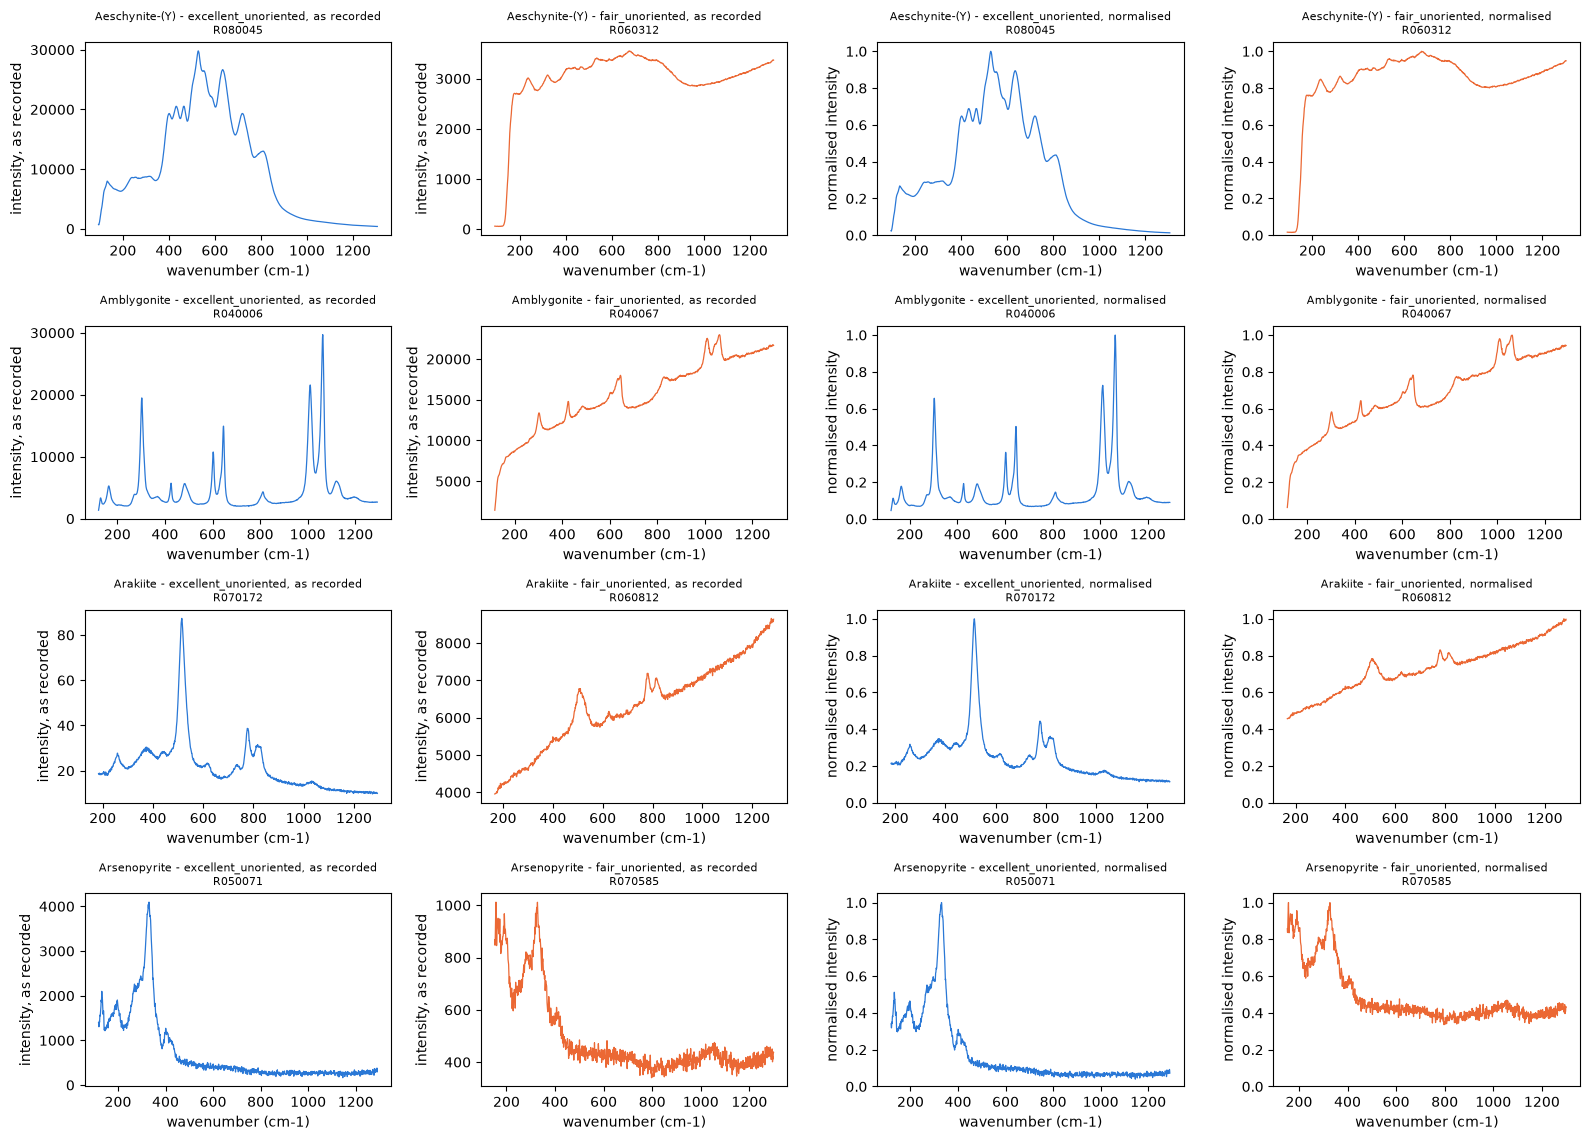

the two archives hold 140 minerals in common at 532 nm; 72 of them have one file in each archive, and the four shown are the first of those in alphabetical order. The first two columns are the recorded intensities and the last two divide each file by its own largest intensity, so a panel is only comparable with itself


In [11]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline


def read_columns(path):
    """The wavenumber and intensity columns of one export's data block.

    Header lines and comment lines inside the block start with a hash, so they are skipped, and a
    line that is not two numbers is passed over.

    Args:
        path (Path): the export to read.

    Returns:
        np.ndarray: one row per data line, holding (wavenumber, intensity), shaped (lines, 2).
    """
    rows = []
    text = path.read_text(encoding="utf-8", errors="replace").replace("\r\n", "\n")
    for line in text.split("\n"):
        stripped = line.strip()
        if not stripped or stripped.startswith("#"):
            continue
        fields = stripped.replace(",", " ").split()
        if len(fields) == 2:
            try:
                rows.append((float(fields[0]), float(fields[1])))
            except ValueError:
                pass
    return np.asarray(rows, dtype=float).reshape(-1, 2)


EXCELLENT = kept[(kept["archive"] == "excellent_unoriented") & (kept["wavelength"] == "532")]
FAIR = kept[(kept["archive"] == "fair_unoriented") & (kept["wavelength"] == "532")]
ARCHIVE_FRAMES = (("excellent_unoriented", EXCELLENT, "#2a78d6"),
                  ("fair_unoriented", FAIR, "#eb6834"))

# The two archives as recorded, then the same two divided by each file's largest intensity.
COLUMN_SPECS = [(archive, frame, colour, normalise)
                for normalise in (False, True)
                for archive, frame, colour in ARCHIVE_FRAMES]

shared = sorted(set(EXCELLENT["mineral"]) & set(FAIR["mineral"]))
single = [name for name in shared
          if len(EXCELLENT[EXCELLENT["mineral"] == name]) == 1
          and len(FAIR[FAIR["mineral"] == name]) == 1]
picked = single[:4]

figure, panels = plt.subplots(len(picked), len(COLUMN_SPECS), figsize=(16, 11.5))
for row, mineral in enumerate(picked):
    for column, (archive, frame, colour, normalise) in enumerate(COLUMN_SPECS):
        panel = panels[row, column]
        record = frame[frame["mineral"] == mineral].iloc[0]
        columns = read_columns(Path(record["path"]))
        intensity, treatment = columns[:, 1], "as recorded"
        if normalise:
            intensity, treatment = intensity / intensity.max(), "normalised"
            panel.set_ylim(0.0, 1.05)
        panel.plot(columns[:, 0], intensity, lw=0.9, color=colour)
        panel.set_title(f"{mineral} - {archive}, {treatment}\n{record['rruff_id']}", fontsize=8)
        panel.set_xlabel("wavenumber (cm-1)")
        panel.set_ylabel("normalised intensity" if normalise else "intensity, as recorded")
plt.tight_layout()
plt.show()

print(f"the two archives hold {len(shared):,} minerals in common at 532 nm; {len(single)} of them "
      f"have one file in each archive, and the four shown are the first of those in alphabetical "
      f"order. The first two columns are the recorded intensities and the last two divide each "
      f"file by its own largest intensity, so a panel is only comparable with itself")


## 12. What this covers

| Section | Reports |
| --- | --- |
| 3 | the files the set keeps, and the RAW and confirmed filter they pass, archive by archive |
| 4 | the number of kept files at each excitation wavelength |
| 5 | the number of minerals those files name at each excitation wavelength |
| 6 | how the files at 514, 532 and 780 nm are spread over the seven archives |
| 7 | how the minerals at 514, 532, 780 and 785 nm are spread over the seven archives |
| 8 | the three largest clusters of each archive, with the files and minerals of each |
| 9 | the minerals each cluster shares with the other archives at its excitation |
| 10 | the clusters of section 9 split by excitation, one table per laser |
| 11 | the spectra of four minerals that both archives hold at 532 nm |

Nothing here trims a file or places it on a shared axis, and no spectrum is read: only the header of
each export is. Section 11 is the one place that reads a data block.


## 13. Reproducing

```
cd /home/raj/projects/SH_Project
MPLBACKEND=Agg .venv/bin/jupyter execute --inplace --kernel_name sh_project notebooks/raw_laser.ipynb
```

The archives are read from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is set.
